# Test Code Execution with Energy Profiling

In [1]:
# Import modules
import lassi.code_manager
import lassi.llm_methods
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.code_manager
%aimport lassi.llm_methods
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary

prompts = PromptDictionary()

In [2]:
# Code to test
folder = "test_codes/jacobi/o3minitest"
code_filename = "jacobi-cuda_main_ee_refactorcode_CUDA_exp_t2.1_pipelineV2_gpt4o_argo_ee_hecb_03-30-2025_t15_15_04_v1.cu"
exe_input_parameters = [""]

with open(folder + "/" + code_filename, 'r') as file:
    refactored_code = file.read()
file.close()

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [3]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/jacobi/o3minitest/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t2.1_pipelineV2_gpt4o_argo_ee_hecb_03-30-2025_t15_15_04_v1.cu', '-o', 'test_codes/jacobi/o3minitest/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t2.1_pipelineV2_gpt4o_argo_ee_hecb_03-30-2025_t15_15_04_v1']

Compilation of code successful!


Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]


Working directory: test_codes/jacobi/o3minitest
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t2.1_pipelineV2_gpt4o_argo_ee_hecb_03-30-2025_t15_15_04_v1', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00400565 (s)
PASS
Total elapsed time: 8.508 seconds
GPU power data has been written to CUDA_CUDA_gpu_power_results.csv


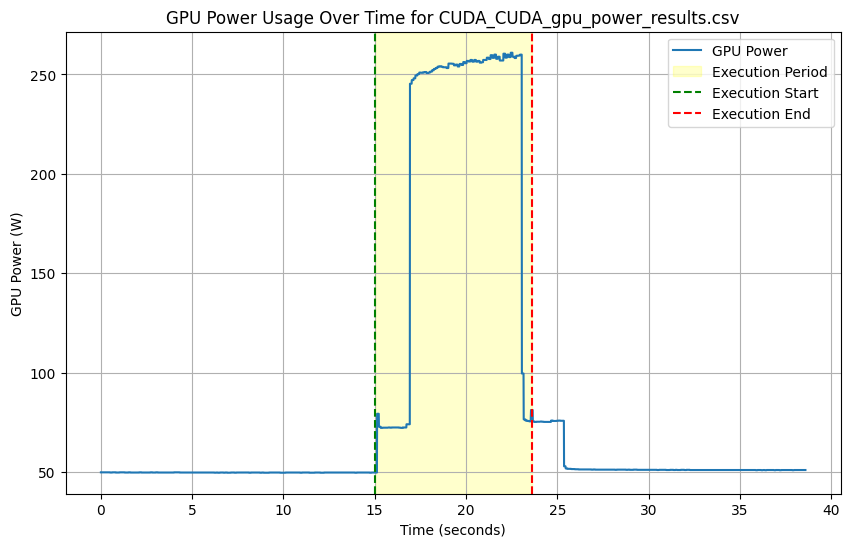

Start time: 15.0 -- End time: 23.598
Total GPU energy consumption for CUDA_CUDA_gpu_power_results.csv:
  0.000485 kWh
  0.4849 Wh
  1745.56 J
Average GPU power: 203.21 W
Total Energy During Exe Runtime:   1745.56 J
Code execution duration: 8.60 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


In [4]:
execute_result, exe_output, total_energy_joules, ave_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Measure system idle power
"""
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)
"""

# Code Validation - LLM-as-a-Judge

In [5]:
# Run source code
# Call llm-as-a-judge method
# Source Code to test
folder = "test_codes/jacobi"
code_filename = "main.cu"
with open(folder + "/" + code_filename, 'r') as file:
    source_code = file.read()
file.close()

In [6]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/jacobi/main.cu', '-o', 'test_codes/jacobi/main']

Compilation of code successful!


Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]


Working directory: test_codes/jacobi
Execute command: ['./main', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00400862 (s)
PASS
Total elapsed time: 7.748 seconds
GPU power data has been written to CUDA_CUDA_gpu_power_results.csv


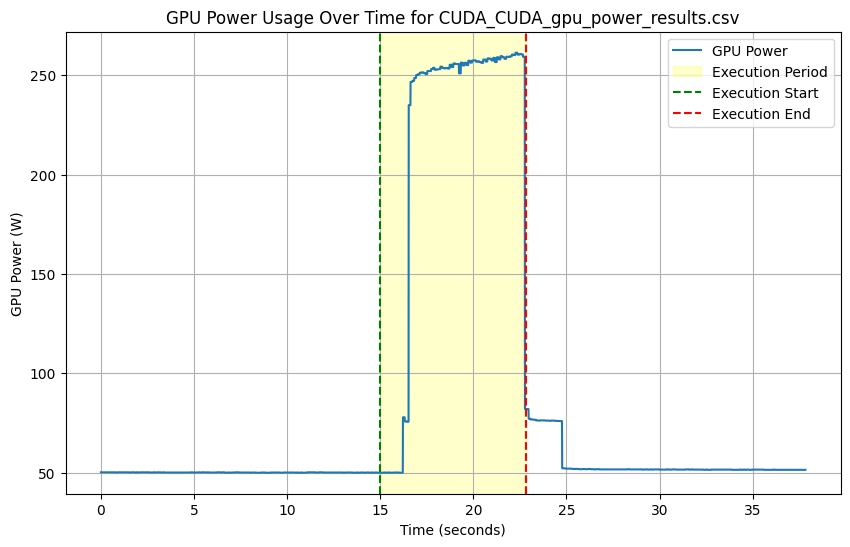

Start time: 15.001 -- End time: 22.835
Total GPU energy consumption for CUDA_CUDA_gpu_power_results.csv:
  0.000467 kWh
  0.4673 Wh
  1682.30 J
Average GPU power: 214.85 W
Total Energy During Exe Runtime:   1682.30 J
Code execution duration: 7.83 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


In [8]:
execute_result_source, exe_output_source, total_energy_joules_source, ave_power_source, duration_source, metrics_results_string_source = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Save source code results into a local JSON file for quick loading

In [9]:
llm_source = "argo"
model_judge = "gpto3mini"
num_ctx = 20000
general_system_prompt = prompts.get_system_prompt("general_system_ee")
input_content_llmjudge_dict = {
    "source_code": source_code,
    "source_stdout": exe_output_source,
    "source_metrics": metrics_results_string_source,
    "refactored_code": refactored_code,
    "refactored_stdout": exe_output,
    "refactored_metrics": metrics_results_string,
} 
display_response = True
verifyprompt = False

# Call LLM-as-a-judge to review SOURCE CODE and REFACTORED CODE to evaluate if likely valid
valid_code_flag = lassi.llm_methods.llm_judge(
    llm_source,
    model_judge,
    num_ctx,
    general_system_prompt,
    input_content_llmjudge_dict,
    display_response,
    verifyprompt
)
print(f"\nResult: {valid_code_flag}")



--> ... prompt LLM to judge the validity of the refactored code.





----- LLM RESPONSE: code validation judge -----



The refactored code retains the core algorithm exactly—the Jacobi relaxation kernel, the halo data handling, the error reduction via warp shuffles, and the data swap kernel are all kept functionally identical. The changes are mainly refactorings aimed at energy efficiency while preserving the algorithm:

1. The refactored code combines nested conditionals (both in the jacobi_step and swap_data kernels) which reduces branch divergence but does not alter the logic.
2. Memory allocation for the host arrays now uses cudaMallocHost (pinned memory) instead of aligned_alloc. This change is beneficial for throughput on data transfers and does not change the outcomes.
3. The cudaMemset call in the loop now properly uses sizeof(float) for clarity, though the original use of “4” didn’t change functionality.
4. Comments indicate the intent of standard math functions remains the same.
5. The standard output (layout and values) remains nearly identical—with only small numerical differences in timings and energy, which are acceptable indicators of improved energy efficiency.

Since functionality, kernel logic, and the printed output are preserved with only eligible minor numerical differences, the refactored code is functionally equivalent to the source code.

VALID



----- END LLM RESPONSE -----


Result: VALID
